In [1]:
import os, sys
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

# Your folder (contains run_eeg_encodings.py + neutnn_lib.py)
PROJECT_DIR = "/content/drive/MyDrive/npy"

print("PROJECT_DIR:", PROJECT_DIR)
print("exists:", os.path.exists(PROJECT_DIR))
print("run_eeg_encodings.py:", os.path.exists(os.path.join(PROJECT_DIR, "run_eeg_encodings.py")))
print("neutnn_lib.py:", os.path.exists(os.path.join(PROJECT_DIR, "neutnn_lib.py")))

# Force PROJECT_DIR to highest priority for imports.
if PROJECT_DIR in sys.path:
    sys.path.remove(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)

print("sys.path[0] =", sys.path[0])

Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/npy
exists: True
run_eeg_encodings.py: True
neutnn_lib.py: True
sys.path[0] = /content/drive/MyDrive/npy


In [2]:
!pip install mne

In [3]:
import os
import math
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

from run_eeg_encodings import _load_eeg, encode_multithreshold_signal
from neutnn_lib import activeDendriteLayer_SNL

cuda = torch.cuda.is_available()
device = torch.device('cuda:0' if cuda else 'cpu')
print('device =', device)

device = cuda:0


In [4]:
# -------------------- Data config (use NPY folder directly) --------------------
NPY_DIR = "/content/drive/MyDrive/npy"

X_train = np.load(os.path.join(NPY_DIR, "X_train.npy"))
y_train = np.load(os.path.join(NPY_DIR, "y_train.npy"))
X_test = np.load(os.path.join(NPY_DIR, "X_test.npy"))
y_test = np.load(os.path.join(NPY_DIR, "y_test.npy"))

# Keep compatibility with downstream cells that still use X_all / y_all.
X_all = np.concatenate([X_train, X_test], axis=0)
y_all = np.concatenate([y_train, y_test], axis=0)

# Use all channels from NPY directly (ignore scalp names).
n_scalp_channels = X_all.shape[1]
selected_idx = list(range(n_scalp_channels))
X_all = X_all[:, selected_idx, :]

exclude_first_class = False
if exclude_first_class:
    keep = y_all != 0
    X_all = X_all[keep]
    y_all = y_all[keep] - 1

n_classes = int(np.unique(y_all).max()) + 1

print('Loaded from:', NPY_DIR)
print('Train:', X_train.shape, y_train.shape)
print('Test:', X_test.shape, y_test.shape)
print('Using all channel indices:', selected_idx)
print('Labels:', np.unique(y_all), '| n_classes:', n_classes)

Loaded from: /content/drive/MyDrive/npy
Train: (30613, 32, 50) (30613,)
Test: (7654, 32, 50) (7654,)
Using all channel indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]
Labels: [0 1 2 3 4] | n_classes: 5


In [5]:
def compute_global_thresholds(X, n_thresholds=5):
    diffs = []
    for i in range(X.shape[0]):
        epoch = X[i]
        for ch in range(epoch.shape[0]):
            diff = np.diff(epoch[ch])
            diffs.append(np.abs(diff))

    diffs = np.concatenate(diffs)

    thresholds = np.percentile(diffs, np.linspace(20, 90, n_thresholds))
    return thresholds

In [6]:
# -------------------- Split: train / test --------------------
# Already loaded from NPY split in the previous cell.
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (30613, 32, 50) | Test: (7654, 32, 50)


In [7]:
class EEGAlg7Dataset(torch.utils.data.Dataset):
    """Encode each EEG epoch with Algorithm 7 (pos/neg multi-threshold spikes)."""

    def __init__(self, X, labels, thresholds, n_thresholds=5, spatial_grid_size=28):
        self.labels = torch.tensor(labels, dtype=torch.long)
        self.thresholds = thresholds
        self.n_thresholds = n_thresholds
        self.spatial_grid_size = spatial_grid_size
        target_shape = (2 * n_thresholds, spatial_grid_size, spatial_grid_size)

        spikes = []
        for i in tqdm(range(X.shape[0])):
            epoch = X[i]  # (C, T)
            ch_spikes = []
            for ch in range(epoch.shape[0]):
                pos, neg = encode_multithreshold_signal(
                    epoch[ch],
                    n_thresholds=n_thresholds,
                    thresholds=thresholds,
                )
                ch_spikes.append(np.concatenate([pos.T, neg.T], axis=0))  # (2K, T-1)
            events = np.stack(ch_spikes, axis=1)  # (2K, C, T-1)
            events = events.reshape(-1, events.shape[-1])
            flat = events.astype(np.float32).ravel()
            need = int(np.prod(target_shape))
            if flat.size >= need:
                arr = flat[:need].reshape(target_shape)
            else:
                pad = np.zeros(need, dtype=np.float32)
                pad[: flat.size] = flat
                arr = pad.reshape(target_shape)
            spikes.append(torch.from_numpy(arr).float())

        self.spikes = torch.stack(spikes)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.spikes[idx], self.labels[idx]

In [8]:
# -------------------- Model params (fixed threshold setting) --------------------
n_thresholds = 5

interval1 = 1000
interval2 = 1000
numSegments = 36

# Learning params
capture = 1
search = 0
backoff = 0.625
frac = 0
wBase = 14
wMax = 16
threshold = 340
voting_thresh = 0
inc_learn = 1
print('Neuron threshold:', threshold)

Neuron threshold: 340


In [9]:
### Active Dendrite Layer ###

    # Implements a single NeuTNN layer with multiple neurons, dendrites, and segments.
    # Segments are assumed to be distal, while the proximal input is simply used as enable during weight update.
    # Capable of online continuous learning via STDP/R-STDP.

    # Args: numDistalInputs - Number of distal inputs to a single neuron. Within a neuron, the inputs are shared across all segments.
    #       numSegments     - Number of segments per dendrite per neuron.
    #       numDendrites    - Number of dendrites per neuron.
    #       numNeurons      - Number of neurons in the layer.
    #       threshold       - Excitation threshold for neuron. An output spike is generated when neuron's body potential reaches
    #                         this threshold.
    #       wMax            - Maximum value for synaptic weights.
    #       wInit           - Type of initialization for synaptic weights. Supports 'zero', 'uniform', and 'normal' initializations.
    #       rewardEn        - Enable reinforcement for STDP (R-STDP).
    #       device          - Device type (e.g. cpu, cuda).
    #
    # Input: data           - Input data to the layer of shape [numNeurons, numDistalInputs].
    #
    # __call__ is the forward function whereas "update" performs STDP update in either unsupervised or supervised fashion.
class activeDendriteLayer(nn.Module):
    def __init__(self,
                 numDistalInputs: int,
                 numSegments: int,
                 numDendrites: int,
                 numNeurons: int,
                 threshold: int,
                 wMax: int = 8,
                 wInit: str = "uniform",
                 rewardEn: bool = True,
                 device="cpu"
                ):

        super(activeDendriteLayer, self).__init__()

        self.numDistalInputs = numDistalInputs
        self.numSegments = numSegments
        self.numDendrites = numDendrites
        self.numNeurons = numNeurons
        self.threshold = threshold
        self.wMax = wMax
        self.wInit = wInit
        self.rewardEn = rewardEn
        self.device = device

        self.totalSegments = self.numNeurons*self.numDendrites*self.numSegments

        if self.wInit       == "zero":
            self.weights   = nn.Parameter(torch.zeros(self.totalSegments,
                                                        self.numDistalInputs), requires_grad=False)

        elif self.wInit     == "uniform":
            self.weights   = nn.Parameter(torch.randint(low = 0, high = self.wMax + 1,
                                            size=(self.totalSegments,
                                                self.numDistalInputs)).type(torch.FloatTensor),
                                            requires_grad=False)

        elif self.wInit     == "normal":
            self.weights   = nn.Parameter(torch.round(( (self.wMax+1)/2 + \
                                                        torch.randn(self.totalSegments, self.numDistalInputs))\
                                                        .clamp_(0,self.wMax)), requires_grad=False)


    ########################################### Inference function ###########################################
    def __call__(self, data):
        # Data is of shape [self.numNeurons, self.numDistalInputs]

        inputData = data.unsqueeze(1).repeat(1,self.numDendrites*self.numSegments,1)\
                        .reshape(self.totalSegments,self.numDistalInputs)

        # Applying weights
        weightedInput = inputData * self.weights

        # Weighted input summation - SNL
        summedOutput = torch.sum(weightedInput, dim=1)

        zeroCondition = summedOutput < self.threshold
        summedOutput[zeroCondition] = 0

        # Winner Take All inhibition across segments
        reshapedSummedOutput = summedOutput.reshape(-1,self.numSegments)

        self.wtaOutput = torch.zeros(self.numNeurons*self.numDendrites, self.numSegments,
                                     dtype=reshapedSummedOutput.dtype, device=self.device)

        maxval, indices = torch.max(reshapedSummedOutput, dim=1)

        self.wtaOutput.scatter_(1, indices.unsqueeze(1), maxval.unsqueeze(1))

        outputData = (self.wtaOutput>0).reshape(-1).unsqueeze(1).repeat(1,self.numDistalInputs)

        return inputData, outputData


    ########################################### Update function ###########################################
    def update(self, inputData, inputLabels, outputData, weights, capture, search, backoff, wBase, rewardEn, frac=0.25):

        if rewardEn:
            captureVal = (inputData == 1) * (outputData == 1) * (inputLabels == 1) * capture + (inputData == 0) * (outputData == 1) * (inputLabels == 0) * capture * frac
            backoffVal = (inputData == 0) * (outputData == 1) * (inputLabels == 1) * backoff + (inputData == 1) * (outputData == 1) * (inputLabels == 0) * backoff * frac
            searchCondition  = (inputData == 1) * (outputData == 0) * (inputLabels == 1)
        else:
            captureVal = (inputData == 1) * (outputData == 1) * capture
            backoffVal = (inputData == 0) * (outputData == 1) * backoff
            searchCondition  = (inputData == 1) * (outputData == 0)

        # Capture and Backoff
        weights += captureVal - backoffVal

        # Search
        weights[searchCondition] = torch.maximum(weights[searchCondition],
                                                 torch.minimum(weights[searchCondition] + search,
                                                               torch.tensor([wBase], device=self.device)))

        return weights.clamp_(0, self.wMax)

In [10]:
# -------------------- Build loaders + model params --------------------
n_thresholds = 5
spatial_grid_size = 28
rfSize = 5
stride = 2
dilation = 1

# IMPORTANT FIX: use fixed thresholds from TRAIN set for both train/test
threshold_mode = "median_geometric"  # "median_geometric" or "percentile"
threshold_scale = 2.0
all_abs_diffs = np.abs(np.diff(X_train, axis=-1)).reshape(-1)
if threshold_mode == "median_geometric":
    threshold_base = float(np.median(all_abs_diffs))
    threshold_base = max(threshold_base, 1e-8)
    thresholds = np.array([threshold_base * (threshold_scale ** i) for i in range(n_thresholds)], dtype=np.float64)
else:
    thresholds = np.percentile(all_abs_diffs, np.linspace(20, 90, n_thresholds))

print("threshold_mode:", threshold_mode)
print("thresholds:", np.round(thresholds, 8))

train_ds = EEGAlg7Dataset(X_train, y_train, thresholds=None, n_thresholds=n_thresholds, spatial_grid_size=spatial_grid_size)
test_ds = EEGAlg7Dataset(X_test, y_test, thresholds=None, n_thresholds=n_thresholds, spatial_grid_size=spatial_grid_size)

train_loader = DataLoader(train_ds, batch_size=1, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=1, shuffle=False)

breakpoint1 = len(train_ds)
breakpoint2 = len(test_ds)
interval1 = 1000
interval2 = 1000

numDistalInputs = (rfSize ** 2) * (2 * n_thresholds)
numSegments = 36
H = spatial_grid_size
W = spatial_grid_size
numNeurons = int((math.floor((H - rfSize) / stride) + 1) * (math.floor((W - rfSize) / stride) + 1))
numDendrites = n_classes

print('target spikes:', train_ds[0][0].shape)
print('numDistalInputs=', numDistalInputs, 'numNeurons=', numNeurons, 'numDendrites=', numDendrites)

threshold_mode: median_geometric
thresholds: [4.930e-06 9.860e-06 1.972e-05 3.945e-05 7.889e-05]


  0%|          | 0/30613 [00:00<?, ?it/s]

  0%|          | 0/7654 [00:00<?, ?it/s]

target spikes: torch.Size([10, 28, 28])
numDistalInputs= 250 numNeurons= 144 numDendrites= 5


In [11]:
def train_func(numDistalInputs, numSegments, numDendrites, numNeurons, threshold, capture, search, backoff, frac, wBase, device, rfSize, wMax, voting_thresh=0, stride=1, dilation=2):

    net = activeDendriteLayer(numDistalInputs = numDistalInputs,
                            numSegments = numSegments,
                            numDendrites = numDendrites,
                            numNeurons = numNeurons,
                            threshold = threshold,
                            wMax=wMax,
                            device = device
                            )

    if cuda:
        net.cuda()

    unfold = nn.Unfold(kernel_size = (rfSize, rfSize), dilation = dilation, stride = stride)

    for epochs in range(1):
        start = time.time()
        error1 = 0
        error2 = 0
        errorlist1 = []
        errorlist2 = []

        for idx, (data,target) in enumerate(tqdm(train_loader, total=breakpoint1, desc='Training', unit='sample')):

            if cuda:
                data                    = data.cuda()
                target                  = target.cuda()

            label = target[0]
            sliced_data = unfold(data).transpose(1,2).squeeze()

            inputData, outputData = net(sliced_data)

            labelCount = torch.max(net.wtaOutput, dim=1)[0] > voting_thresh
            labelCount = labelCount.reshape(-1,numDendrites)
            labelVotes = torch.sum(labelCount, dim=0)

            if torch.argmax(labelVotes) != label:
                error1 += 1
                error2 += 1
            
            label_idx = int(label.item())

            inputLabels = torch.zeros(
                (net.numNeurons, net.numDendrites, net.numSegments * net.numDistalInputs),
                device=device,
                dtype=torch.float32,
            )
            inputLabels[:, label_idx, :] = 1.0
            inputLabels = inputLabels.reshape(net.totalSegments, net.numDistalInputs)

            net.weights = net.update(inputData, inputLabels, outputData, net.weights,\
                                                            capture, search, backoff, wBase, net.rewardEn, frac)

            if (idx+1)%interval1 == 0:
                errorlist1.append(error1/(idx+1))
                errorlist2.append(error2/interval1)
                tqdm.write(f'Train samples {idx+1}/{breakpoint1} | running err: {error1/(idx+1):.2%}')
                error2 = 0

        end = time.time()
        training_acc = (breakpoint1-error1)*100/breakpoint1
        print("Training for {0} samples done in {1}".format(idx, end-start))
        print("Training Accuracy for {1} epochs: {0}%".format(training_acc, epochs+1))

    error3 = 0
    start = time.time()

    for idx, (data,target) in enumerate(tqdm(test_loader, total=breakpoint2, desc='Testing', unit='sample')):

        if cuda:
            data                    = data.cuda()
            target                  = target.cuda()

        label = target[0]
        sliced_data = unfold(data).transpose(1,2).squeeze()

        inputData, outputData = net(sliced_data)

        labelCount = torch.max(net.wtaOutput, dim=1)[0] > voting_thresh
        labelCount = labelCount.reshape(-1,numDendrites)
        labelVotes = torch.sum(labelCount, dim=0)

        if torch.argmax(labelVotes) != label:
            error1 += 1
            error2 += 1
            error3 += 1

        if inc_learn == 1:
            label_idx = int(label.item())
            inputLabels = torch.zeros(
                (net.numNeurons, net.numDendrites, net.numSegments * net.numDistalInputs),
                device=device,
                dtype=torch.float32,
            )
            inputLabels[:, label_idx, :] = 1.0
            inputLabels = inputLabels.reshape(net.totalSegments, net.numDistalInputs)

            net.weights = net.update(inputData, inputLabels, outputData, net.weights,\
                                                            capture, search, backoff, wBase, net.rewardEn, frac)

        if (idx+1)%interval2 == 0:
            errorlist1.append(error1/(idx+1+breakpoint1))
            errorlist2.append(error2/interval2)
            error2 = 0

    end = time.time()
    testing_acc = (breakpoint2-error3)*100/breakpoint2
    print("Testing for {0} samples done in {1}".format(idx, end-start))
    print("Testing Accuracy: {0}%".format(testing_acc))

    return training_acc, testing_acc, errorlist2, net

In [12]:
training_accuracy, testing_accuracy, errorlist2, myNetwork = train_func(
    numDistalInputs=numDistalInputs,
    numSegments=numSegments,
    numDendrites=numDendrites,
    numNeurons=numNeurons,
    threshold=threshold,
    capture=capture,
    search=search,
    backoff=backoff,
    frac=frac,
    wBase=wBase,
    device=device,
    rfSize=rfSize,
    wMax=wMax,
    voting_thresh=voting_thresh,
    stride=stride,
    dilation=dilation,
)

print('Final Train Acc:', training_accuracy)
print('Final Test  Acc:', testing_accuracy)

Training:   0%|          | 0/30613 [00:00<?, ?sample/s]

Train samples 1000/30613 | running err: 82.90%
Train samples 2000/30613 | running err: 81.85%
Train samples 3000/30613 | running err: 81.03%
Train samples 4000/30613 | running err: 80.70%
Train samples 5000/30613 | running err: 80.06%
Train samples 6000/30613 | running err: 79.90%
Train samples 7000/30613 | running err: 79.69%
Train samples 8000/30613 | running err: 79.34%
Train samples 9000/30613 | running err: 79.06%
Train samples 10000/30613 | running err: 78.74%
Train samples 11000/30613 | running err: 78.15%
Train samples 12000/30613 | running err: 77.91%
Train samples 13000/30613 | running err: 77.65%
Train samples 14000/30613 | running err: 77.36%
Train samples 15000/30613 | running err: 77.03%
Train samples 16000/30613 | running err: 76.84%
Train samples 17000/30613 | running err: 76.59%
Train samples 18000/30613 | running err: 76.31%
Train samples 19000/30613 | running err: 75.99%
Train samples 20000/30613 | running err: 75.80%
Train samples 21000/30613 | running err: 75.60%
T

Testing:   0%|          | 0/7654 [00:00<?, ?sample/s]

Testing for 7653 samples done in 63.7007417678833
Testing Accuracy: 32.126992422262866%
Final Train Acc: 26.436481233462906
Final Test  Acc: 32.126992422262866


In [13]:
x0, y0 = train_ds[0]
print("sample shape:", x0.shape, "label:", y0)
for data, target in train_loader:
    print("batch shape:", data.shape, "target shape:", target.shape)
    break

sample shape: torch.Size([10, 28, 28]) label: tensor(0)
batch shape: torch.Size([1, 10, 28, 28]) target shape: torch.Size([1])


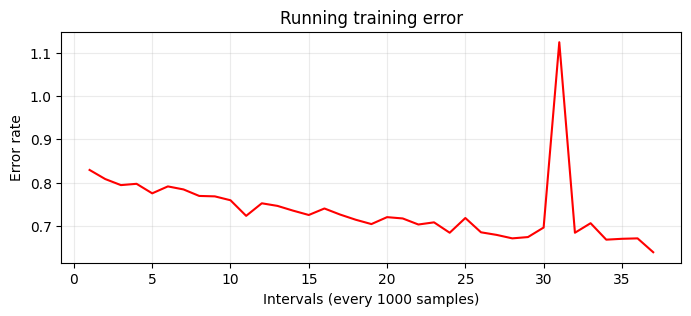

In [14]:
# Optional: plot running training error
if len(errorlist2) > 0:
    dx = np.arange(1, len(errorlist2) + 1)
    plt.figure(figsize=(8, 3))
    plt.plot(dx, errorlist2, color='red', linewidth=1.5)
    plt.title('Running training error')
    plt.xlabel(f'Intervals (every {interval1} samples)')
    plt.ylabel('Error rate')
    plt.grid(alpha=0.25)
    plt.show()
else:
    print('No interval points yet (dataset smaller than interval1).')

Collected 7654 test samples for matching plot.
Classification matching plot shown inline | acc=49.07%


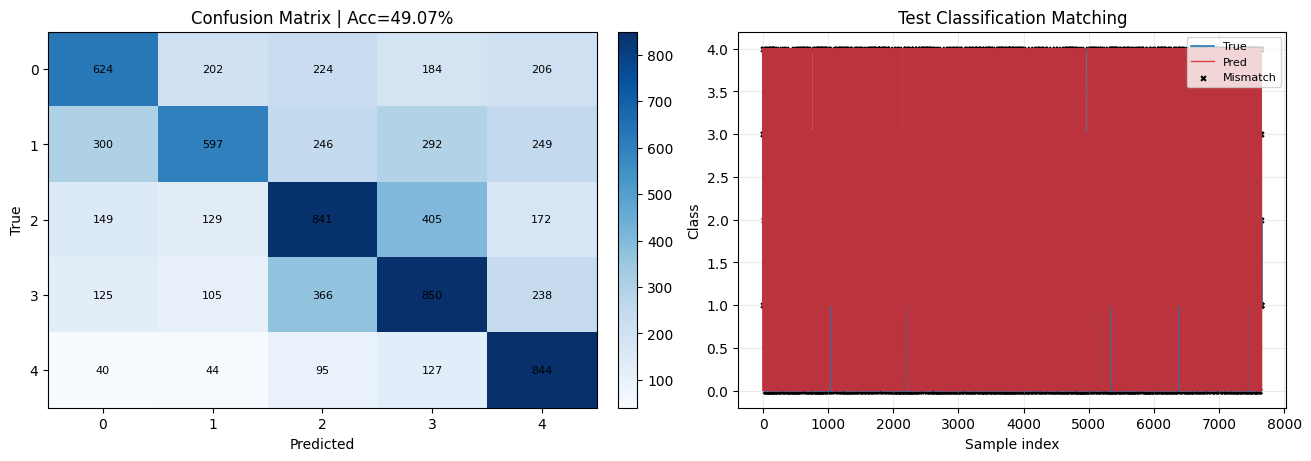

In [15]:
from run_eeg_encodings import plot_classification_matching

# Build y_true / y_pred from trained myNetwork on test_loader, then visualize.
myNetwork.eval()
unfold_eval = nn.Unfold(kernel_size=(rfSize, rfSize), dilation=dilation, stride=stride)

y_true, y_pred = [], []
with torch.no_grad():
    for data, target in test_loader:
        if cuda:
            data = data.cuda()
            target = target.cuda()

        label = int(target[0].item())
        sliced_data = unfold_eval(data).transpose(1, 2).squeeze()
        if sliced_data.dim() == 1:
            sliced_data = sliced_data.unsqueeze(0)

        _inputData, _outputData = myNetwork(sliced_data)
        labelCount = (torch.max(myNetwork.wtaOutput, dim=1)[0] > voting_thresh)
        labelCount = labelCount.reshape(-1, numDendrites)
        labelVotes = torch.sum(labelCount, dim=0)
        pred = int(torch.argmax(labelVotes).item())

        y_true.append(label)
        y_pred.append(pred)

print('Collected', len(y_true), 'test samples for matching plot.')
plot_classification_matching(y_true, y_pred, out_path='')  # inline
# plot_classification_matching(y_true, y_pred, out_path='/content/test_match.png')

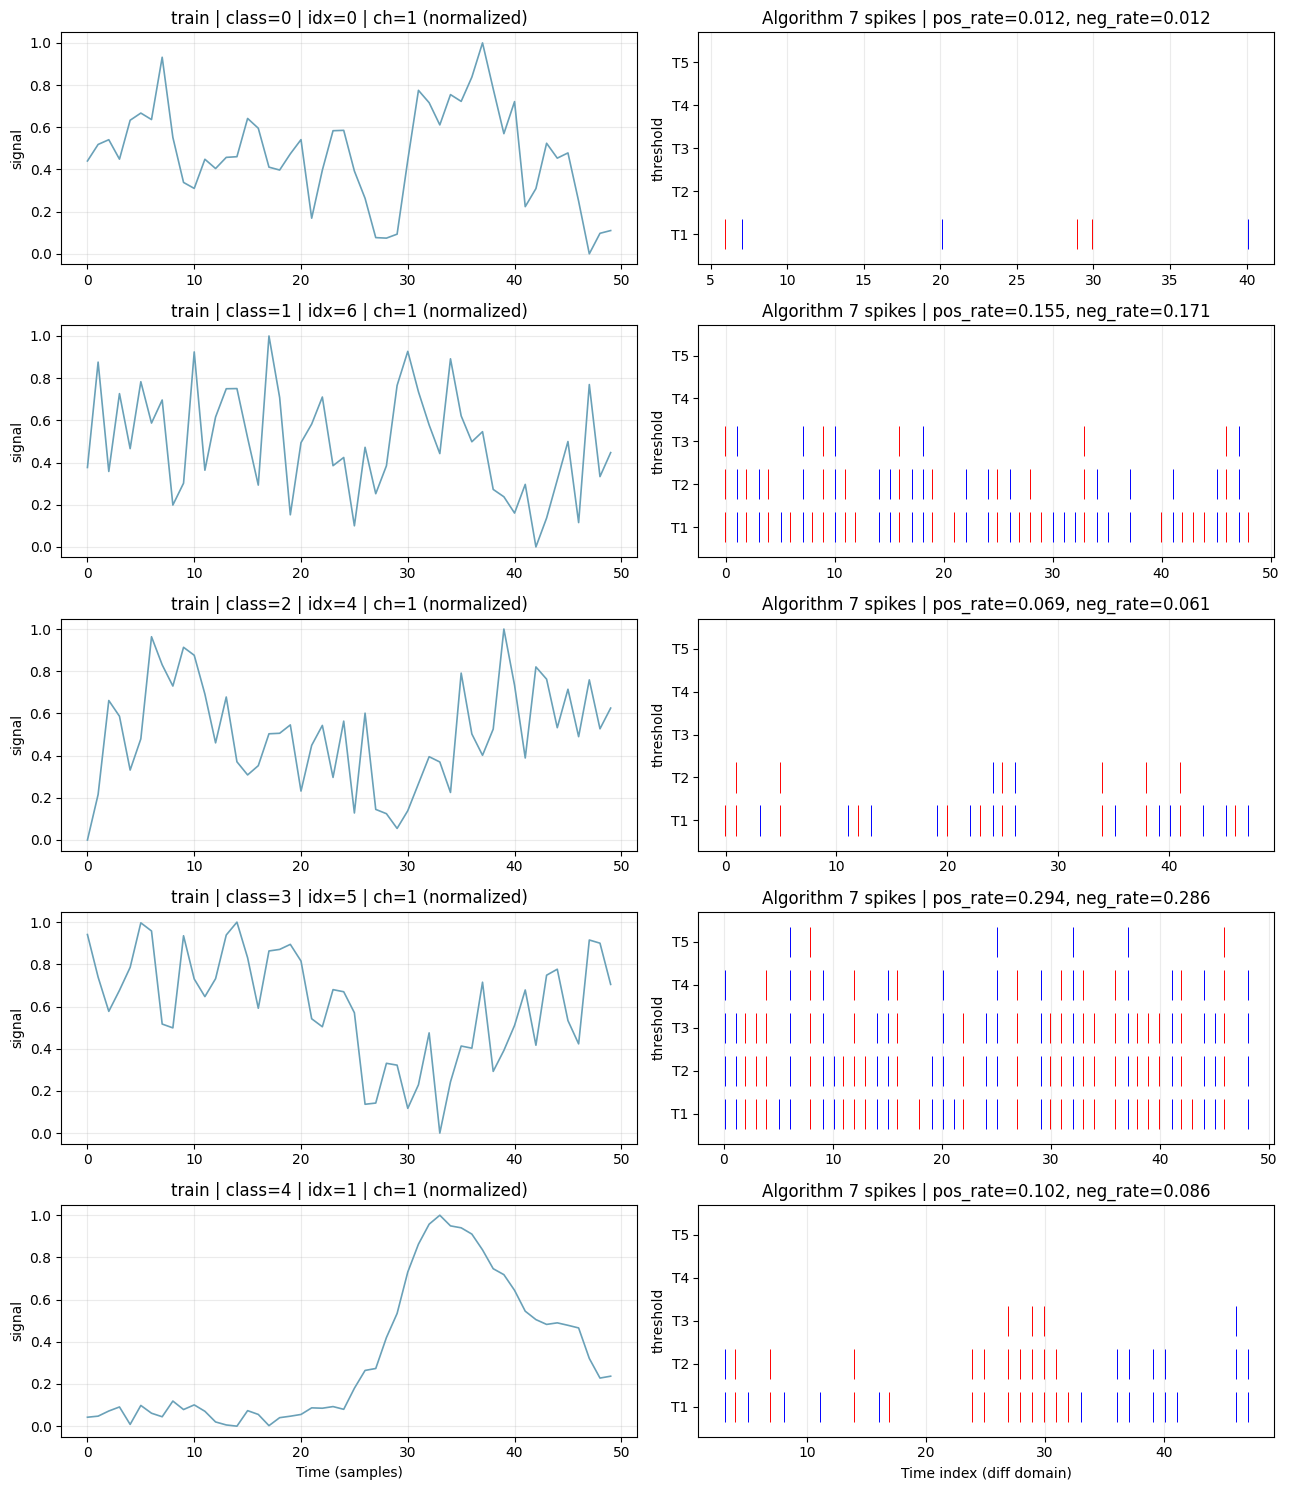

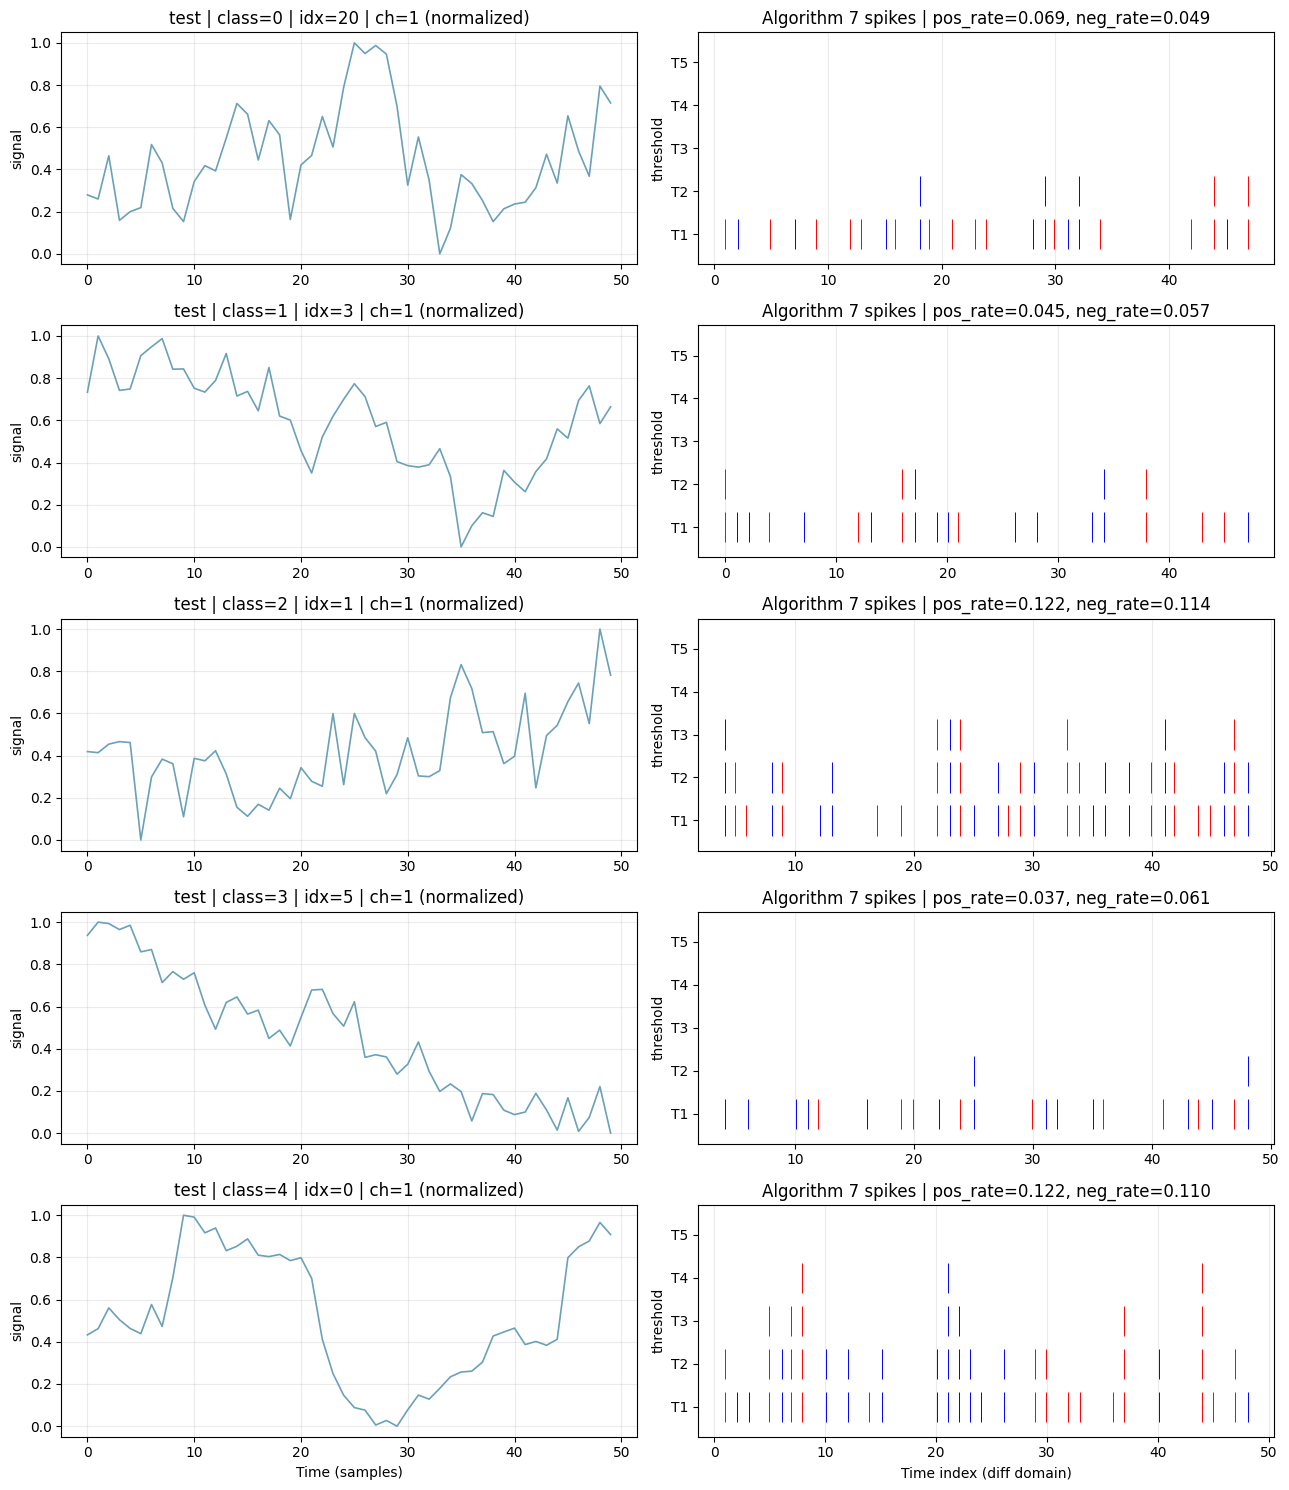

In [16]:
# -------------------- Session-style spike comparison from train_ds / test_ds --------------------
# Same plotting style: left=signal, right=red/blue vertical spike raster.
# NOTE: merged ds stores (2K, H, W); for channel-specific raster we re-encode from X_raw with notebook encoder.

def _minmax_norm(x):
    x = np.asarray(x, dtype=np.float32)
    mn, mx = x.min(), x.max()
    if mx - mn < 1e-8:
        return np.zeros_like(x)
    return (x - mn) / (mx - mn)


def _pick_first_idx_per_class(y):
    idxs = []
    for cls in sorted(np.unique(y).tolist()):
        found = np.where(y == cls)[0]
        if len(found) > 0:
            idxs.append((int(cls), int(found[0])))
    return idxs


def plot_session_style_from_ds(ds, X_raw, y_raw, split_name="train", channel=1, max_rows=6):
    pairs = _pick_first_idx_per_class(y_raw)[:max_rows]
    if len(pairs) == 0:
        print(f"[{split_name}] No class samples found.")
        return

    fig, axes = plt.subplots(len(pairs), 2, figsize=(13, 3 * len(pairs)), squeeze=False)

    for r, (cls, idx) in enumerate(pairs):
        ax_sig = axes[r, 0]
        ax_spk = axes[r, 1]

        signal = X_raw[idx]   # (C, T)
        ch = min(int(channel), signal.shape[0] - 1)
        sig = _minmax_norm(signal[ch])

        # Use notebook encoder directly on this channel for session-style raster.
        pos_tk, neg_tk = encode_multithreshold_signal(
            signal[ch],
            n_thresholds=n_thresholds,
            thresholds=thresholds,
        )
        pos = pos_tk.T  # (K, T-1)
        neg = neg_tk.T  # (K, T-1)
        K, M = pos.shape

        # left: signal
        ax_sig.plot(np.arange(sig.shape[0]), sig, color="#6aa1b8", linewidth=1.2)
        ax_sig.set_title(f"{split_name} | class={cls} | idx={idx} | ch={ch} (normalized)")
        ax_sig.set_ylabel("signal")
        ax_sig.grid(alpha=0.25)

        # right: raster (same threshold line, red=pos, blue=neg)
        m = np.arange(M)
        for k in range(K):
            m_pos = m[pos[k] == 1]
            m_neg = m[neg[k] == 1]
            if m_pos.size > 0:
                ax_spk.vlines(m_pos - 0.08, k - 0.35, k + 0.35, colors="red", linewidth=0.7)
            if m_neg.size > 0:
                ax_spk.vlines(m_neg + 0.08, k - 0.35, k + 0.35, colors="blue", linewidth=0.7)

        pos_rate = float(pos.mean()) if pos.size > 0 else 0.0
        neg_rate = float(neg.mean()) if neg.size > 0 else 0.0
        ax_spk.set_title(f"Algorithm 7 spikes | pos_rate={pos_rate:.3f}, neg_rate={neg_rate:.3f}")
        ax_spk.set_ylabel("threshold")
        ax_spk.set_ylim(-0.7, K - 0.3)
        ax_spk.set_yticks(np.arange(K))
        ax_spk.set_yticklabels([f"T{k+1}" for k in range(K)])
        ax_spk.grid(alpha=0.25, axis="x")

    axes[-1, 0].set_xlabel("Time (samples)")
    axes[-1, 1].set_xlabel("Time index (diff domain)")
    plt.tight_layout()
    plt.show()


# Run for both splits (edit channel if needed)
session_like_channel = 1
plot_session_style_from_ds(train_ds, X_train, y_train, split_name="train", channel=session_like_channel)
plot_session_style_from_ds(test_ds, X_test, y_test, split_name="test", channel=session_like_channel)